Data Partitions:
     CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0             1                  15                      39        2
1             2                  15                      81        0
2             3                  16                       6        1
3             4                  16                      77        0
4             5                  17                      40        2
..          ...                 ...                     ...      ...
195         196                 120                      79       -1
196         197                 126                      28       -1
197         198                 126                      74       -1
198         199                 137                      18       -1
199         200                 137                      83       -1

[200 rows x 4 columns]

Number of points in each partition:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, d

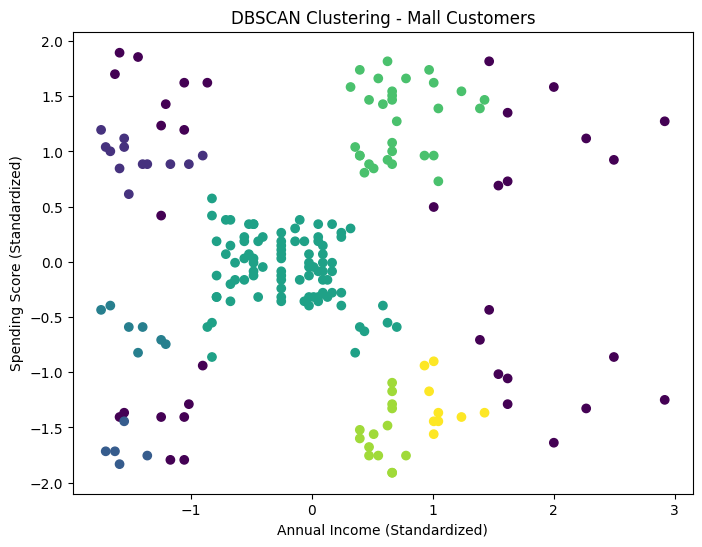

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

data = pd.read_csv("Mall_customers.csv")

X = data[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

data['Cluster'] = labels

print("Data Partitions:")
print(data[['CustomerID', 'Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']])

print("\nNumber of points in each partition:")
print(data['Cluster'].value_counts().sort_index())

plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap='viridis')
plt.xlabel('Annual Income (Standardized)')
plt.ylabel('Spending Score (Standardized)')
plt.title('DBSCAN Clustering - Mall Customers')
plt.show()